# Lab 2: timing plots

Reads `results/*.csv` written by `scripts/bench.sh` and draws time, speedup
and efficiency against the number of workers (OpenMP threads or MPI
processes) for every variant. The figures are also saved as PNGs in
`results/` for `README.md`.

Speedup is `S = T_seq / T_p`, where `T_seq` is the sequential program at the
same size, and efficiency is `E = S / p`. Each time is the minimum over the
repetitions. For MPI, `total` includes collecting the result on rank 0 and
`compute` is the loop alone.

Re-run from the repository root:
`.venv/bin/jupyter nbconvert --to notebook --execute --inplace lab_2/plots.ipynb`

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RESULTS = Path("results")
df = pd.concat(pd.read_csv(f) for f in sorted(RESULTS.glob("*.csv")))
seq = df[df.impl == "seq"].set_index(["variant", "isize"])["min_s"]
df["t_seq"] = [seq[(v.split("-")[0], n)] for v, n in zip(df.variant, df.isize)]
df["speedup"] = df.t_seq / df.min_s
df["efficiency"] = df.speedup / df.workers
df["speedup_comp"] = df.t_seq / df.comp_s
df["efficiency_comp"] = df.speedup_comp / df.workers
par = df[df.impl != "seq"]
par.head()

,variant,impl,isize,jsize,workers,reps,min_s,mean_s,comp_s,t_seq,speedup,efficiency,speedup_comp,efficiency_comp
1,1b,mpi,1000,1000,1,30,0.002603,0.002679,0.002603,0.002688,1.032655,1.032655,1.032655,1.032655
2,1b,mpi,1000,1000,2,30,0.001505,0.001568,0.001382,0.002688,1.786047,0.893023,1.945007,0.972504
3,1b,mpi,1000,1000,4,30,0.000911,0.001025,0.000711,0.002688,2.950604,0.737651,3.780591,0.945148
4,1b,mpi,1000,1000,6,30,0.001229,0.001722,0.000999,0.002688,2.187144,0.364524,2.690691,0.448448
5,1b,mpi,1000,1000,8,30,0.001301,0.001606,0.000923,0.002688,2.066103,0.258263,2.912243,0.364030


In [2]:
# Color follows the implementation, line style the problem size.
COLORS = {"omp": "#2a78d6", "mpi": "#eb6834", "mpi compute": "#1baf7a",
          "omp 2b-cols": "#eda100"}
STYLES = {5000: dict(ls="-", marker="o"), 1000: dict(ls="--", marker="s")}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def series(variant):
    out = []
    sub = par[par.variant.str.startswith(variant)]
    for (name, impl), g in sub.groupby(["variant", "impl"]):
        key = impl if name == variant else f"{impl} {name}"
        out.append((key, g, "min_s", "speedup", "efficiency"))
        if impl == "mpi":
            out.append(("mpi compute", g, "comp_s", "speedup_comp",
                        "efficiency_comp"))
    return out


def plot_variant(variant):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for key, g, t_col, s_col, e_col in series(variant):
        for n, gn in g.groupby("isize"):
            gn = gn.sort_values("workers")
            kw = dict(color=COLORS[key], lw=2, ms=6, label=f"{key}, {n}x{n}",
                      **STYLES[n])
            axes[0].plot(gn.workers, gn[t_col] * 1e3, **kw)
            axes[1].plot(gn.workers, gn[s_col], **kw)
            axes[2].plot(gn.workers, gn[e_col], **kw)
    p = sorted(par.workers.unique())
    axes[1].plot(p, p, color="#8a8984", ls=":", lw=1.5, label="ideal")
    axes[2].axhline(1, color="#8a8984", ls=":", lw=1.5)
    axes[0].set_yscale("log")
    for ax, title in zip(axes, ["time, ms (log)", "speedup", "efficiency"]):
        ax.set_title(f"{variant}: {title}")
        ax.set_xlabel("workers (threads or processes)")
        ax.set_xticks(p)
    axes[2].set_ylim(0, 1.15)
    axes[1].legend(fontsize=8, loc="upper left")
    fig.tight_layout()
    fig.savefig(RESULTS / f"{variant}.png")
    plt.show()

## Reference loop (OpenMP and MPI)

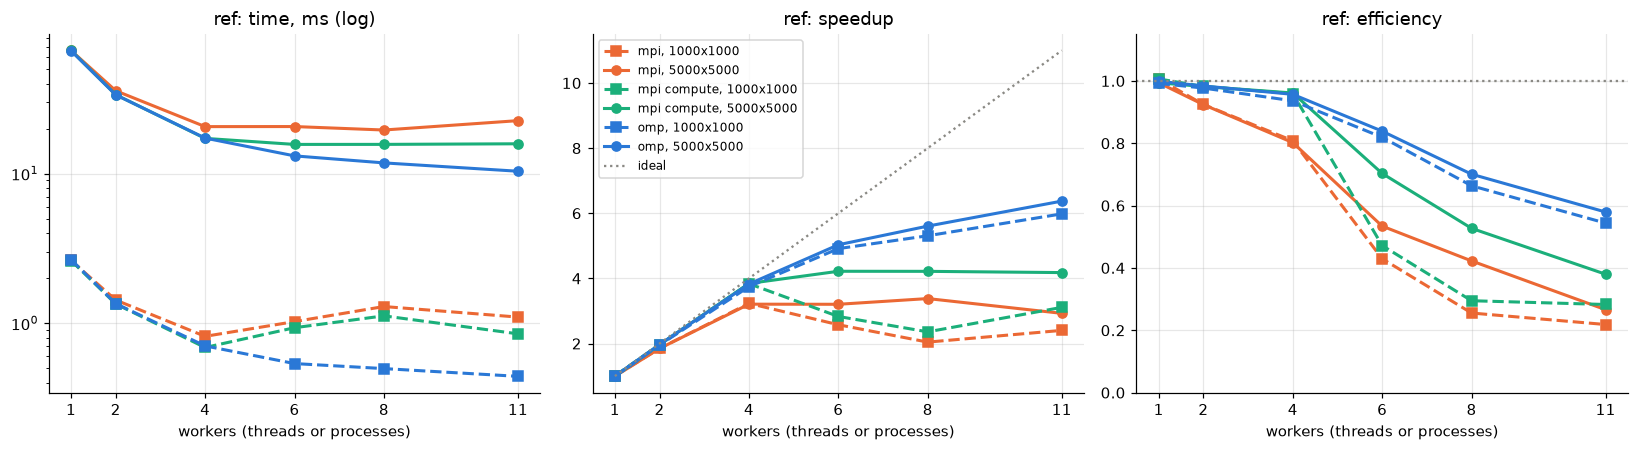

In [3]:
plot_variant("ref")

## Variant 1b (MPI)

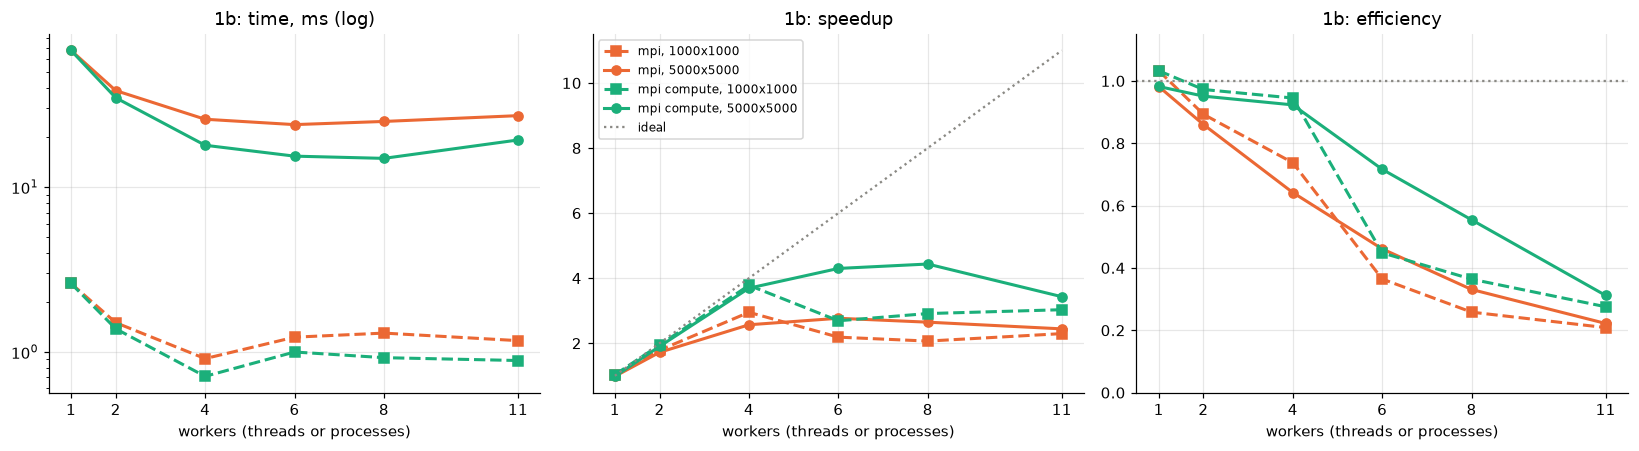

In [4]:
plot_variant("1b")

## Variant 2b (OpenMP): row blocks (`2b`) and per-row column split (`2b-cols`)

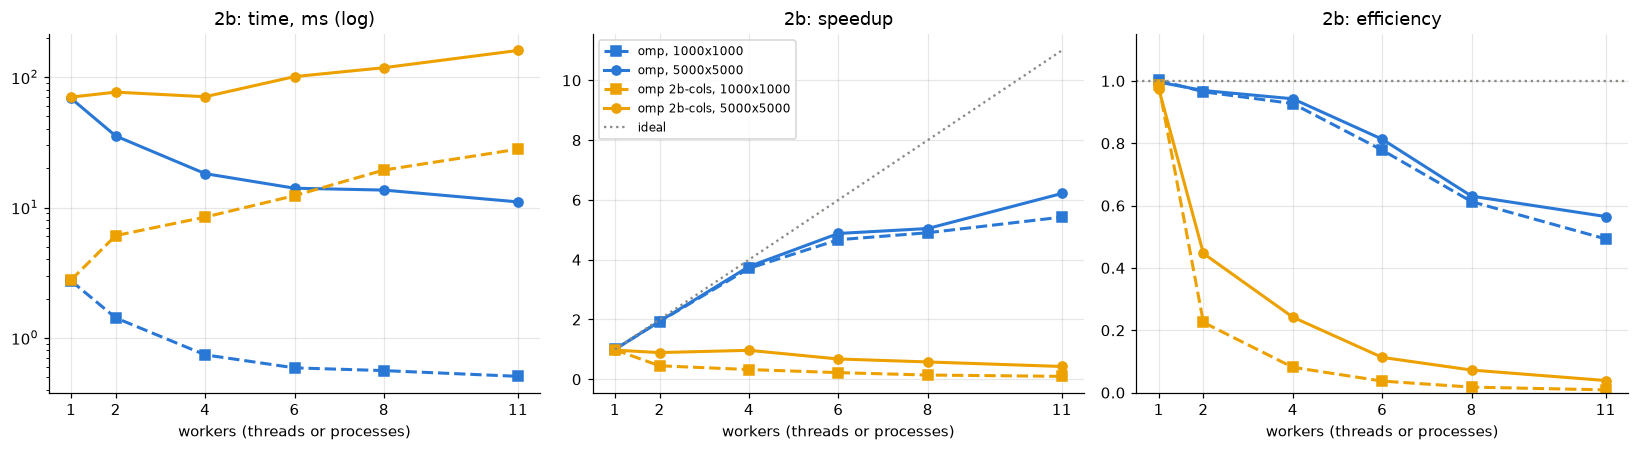

In [5]:
plot_variant("2b")

## Variant 3b (OpenMP)

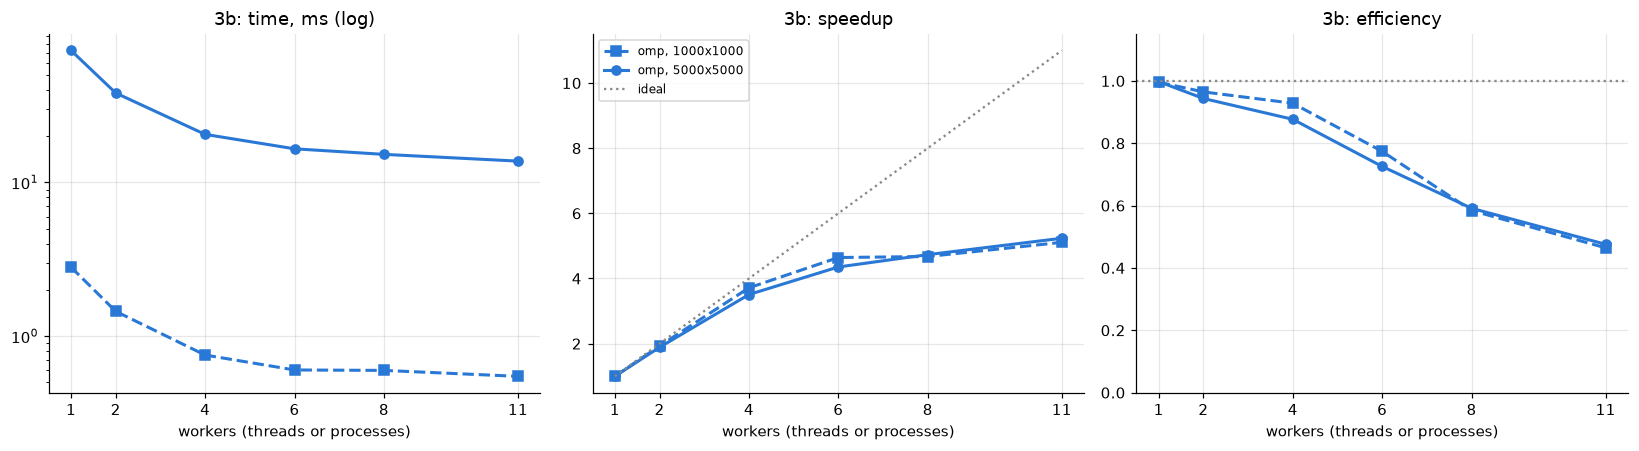

In [6]:
plot_variant("3b")

## Summary at 5000 x 5000

In [7]:
big = par[par.isize == 5000].copy()
big["label"] = big.variant + " " + big.impl
table = big.pivot_table(index="workers", columns="label", values="speedup")
table.round(2)

label,1b mpi,2b omp,2b-cols omp,3b omp,ref mpi,ref omp
workers,,,,,,
1,0.98,1.00,0.98,1.00,0.99,1.00
2,1.72,1.94,0.89,1.89,1.85,1.97
4,2.57,3.77,0.97,3.51,3.21,3.83
6,2.77,4.88,0.68,4.35,3.20,5.03
8,2.65,5.04,0.58,4.73,3.38,5.61
11,2.44,6.21,0.43,5.23,2.93,6.37


In [8]:
eff = big.pivot_table(index="workers", columns="label", values="efficiency")
eff.round(2)

label,1b mpi,2b omp,2b-cols omp,3b omp,ref mpi,ref omp
workers,,,,,,
1,0.98,1.00,0.98,1.00,0.99,1.00
2,0.86,0.97,0.45,0.94,0.92,0.98
4,0.64,0.94,0.24,0.88,0.80,0.96
6,0.46,0.81,0.11,0.73,0.53,0.84
8,0.33,0.63,0.07,0.59,0.42,0.70
11,0.22,0.56,0.04,0.48,0.27,0.58
